In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.feature_selection import SelectKBest
from sklearn.impute import SimpleImputer
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import MinMaxScaler

# Bắt đầu từ vị trí folder Source
source_path = Path.cwd().parent.parent
if str(source_path) not in sys.path:
    sys.path.append(str(source_path))

from data_loader import DATASETS, load_dataset, make_preprocessor, _information_gain
from knn_model import KNNModel
from baseline.standard_knn import StandardKNN, get_standard_knn
from baseline.c50 import C50Classifier, get_c50

CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
print("Datasets:", DATASETS)

Datasets: ('glass', 'iris', 'heart', 'wine', 'diabetes', 'aust')


In [ ]:
def build_preprocessor(k: int | str = "all", use_ohe: bool = False, dataset_name: str | None = None) -> Pipeline:
    """Tạo pipeline tiền xử lý cục bộ theo từng fold."""
    if use_ohe:
        if dataset_name is None:
            raise ValueError("Cần truyền dataset_name khi use_ohe=True.")
        return make_preprocessor(dataset_name, k=k)

    steps = [
        ("impute", SimpleImputer(strategy="median")),
        ("scale", MinMaxScaler()),
    ]
    if k != "all":
        steps.append(("select", SelectKBest(score_func=_information_gain, k=k)))
    return Pipeline(steps)


def evaluate_model(
    dataset_name: str,
    clf,
    k: int | str = "all",
    use_ohe: bool = False,
    cv=CV,
) -> dict:
    """Chạy 5-fold CV và trả về Accuracy (%), số đại diện trung bình và Reduction Rate (%)."""
    X, y = load_dataset(dataset_name)
    pipe = Pipeline([
        ("prep", build_preprocessor(k=k, use_ohe=use_ohe, dataset_name=dataset_name)),
        ("clf", clf),
    ])

    is_knn_model = isinstance(clf, KNNModel)
    res = cross_validate(
        pipe, X, y, cv=cv, scoring="accuracy", return_estimator=is_knn_model
    )

    out = {
        "acc_mean": res["test_score"].mean() * 100,
        "acc_std": res["test_score"].std() * 100,
        "avg_reps": np.nan,
        "rr_mean": 0.0,
    }

    if is_knn_model:
        estimators = [est.named_steps["clf"] for est in res["estimator"]]
        out["avg_reps"] = float(np.mean([e.n_representatives_ for e in estimators]))
        out["rr_mean"] = float(np.mean([e.reduction_rate_ for e in estimators]))

    return out


def plot_knn_r_curve(
    x,
    y,
    title: str = "",
    ylim=None,
    figsize=(7.5, 3.2),
):
    fig, ax = plt.subplots(figsize=figsize, facecolor="white")
    ax.set_facecolor("#C0C0C0")

    ax.plot(
        x, y,
        color="#000080",
        marker="D",
        markersize=4.5,
        linewidth=1.5,
        zorder=3,
    )

    ax.yaxis.grid(True, color="black", linestyle="-", linewidth=0.8, zorder=0)
    ax.xaxis.grid(False)

    ax.set_xticks(x)
    ax.set_xlim(min(x) - 0.5, max(x) + 0.5)
    ax.set_xlabel("Error Tolerant Degree $r$", fontsize=11, labelpad=8)
    ax.set_ylabel("Accuracy percentage", fontsize=11)

    if title:
        ax.set_title(title, fontsize=11, pad=8)
    if ylim is not None:
        ax.set_ylim(ylim)

    ax.tick_params(axis="both", direction="out", length=4, width=1, colors="black")
    for spine in ax.spines.values():
        spine.set_color("black")
        spine.set_linewidth(0.8)

    fig.patch.set_edgecolor("black")
    fig.patch.set_linewidth(1.5)

    plt.tight_layout(pad=1.5)
    plt.show()

In [ ]:
table2_rows = []
table3_reps_rows = []
table3_rr_rows = []

# Có thể tùy chỉnh k theo từng dataset nếu muốn bật Feature Selection, mặc định "all"
FEATURE_K = {ds: "all" for ds in DATASETS}  

for ds in DATASETS:
    X, _ = load_dataset(ds)
    k_feat = FEATURE_K[ds]

    row_acc = {"Dataset": ds.capitalize()}
    row_reps = {"Dataset": ds.capitalize()}
    row_rr = {"Dataset": ds.capitalize()}

    # Baseline 2: C5.0
    row_acc["C5.0"] = evaluate_model(ds, get_c50(), k=k_feat)["acc_mean"]

    # KNNModel với r=1 và N > 1..5 (tương ứng N = 1..5 trong KNNModel)
    for n_val in range(1, 6):
        metrics = evaluate_model(ds, KNNModel(r=1, N=n_val, metric="euclidean"), k=k_feat)
        col = f"N>{n_val}"
        row_acc[col] = metrics["acc_mean"]
        row_reps[col] = metrics["avg_reps"]
        row_rr[col] = metrics["rr_mean"]

    row_reps["kNN (Total)"] = len(X)

    # Baseline 1: Standard k-NN (k = 1, 3, 5)
    for k_nn in (1, 3, 5):
        row_acc[f"K={k_nn}"] = evaluate_model(ds, get_standard_knn(k=k_nn), k=k_feat)["acc_mean"]

    table2_rows.append(row_acc)
    table3_reps_rows.append(row_reps)
    table3_rr_rows.append(row_rr)

df_table2 = pd.DataFrame(table2_rows).set_index("Dataset")
df_table2.loc["Average"] = df_table2.mean()

df_table3_reps = pd.DataFrame(table3_reps_rows).set_index("Dataset")
df_table3_rr = pd.DataFrame(table3_rr_rows).set_index("Dataset")
df_table3_rr.loc["Average"] = df_table3_rr.mean()

print("=== TABLE 2: Classification Accuracy (%) ===")
display(df_table2.round(2))

print("=== TABLE 3a: Average Number of Representatives (per fold) ===")
display(df_table3_reps.round(1))

print("=== TABLE 3b: Average Reduction Rate (%) ===")
display(df_table3_rr.round(2))

=== TABLE 2: Classification Accuracy (%) ===


,C5.0,N>1,N>2,N>3,N>4,N>5,K=1,K=3,K=5
Dataset,,,,,,,,,
Glass,71.50,70.58,69.62,66.83,60.29,58.90,70.53,67.29,63.98
Iris,95.33,94.00,94.67,94.00,94.00,92.00,95.33,95.33,96.00
Heart,72.22,78.52,80.37,78.89,80.74,81.11,71.11,78.15,78.89
Wine,91.52,96.08,96.08,94.97,94.41,94.41,95.51,96.06,96.08
Diabetes,69.27,72.78,73.43,73.82,73.04,73.55,70.57,72.78,72.00
Aust,82.03,84.06,84.64,84.35,84.64,83.62,79.71,83.48,84.64
Average,80.31,82.67,83.14,82.14,81.19,80.60,80.46,82.18,81.93


=== TABLE 3a: Average Number of Representatives (per fold) ===


,N>1,N>2,N>3,N>4,N>5,kNN (Total)
Dataset,,,,,,
Glass,24.6,16.0,11.8,8.4,6.6,214
Iris,5.6,5.2,4.6,4.4,3.8,150
Heart,24.8,18.0,14.4,11.8,10.6,270
Wine,6.4,5.2,4.0,3.0,3.0,178
Diabetes,85.2,65.8,53.2,40.6,34.0,768
Aust,47.6,39.8,33.4,27.8,26.8,690


=== TABLE 3b: Average Reduction Rate (%) ===


,N>1,N>2,N>3,N>4,N>5
Dataset,,,,,
Glass,85.63,90.65,93.11,95.09,96.15
Iris,95.33,95.67,96.17,96.33,96.83
Heart,88.52,91.67,93.33,94.54,95.09
Wine,95.51,96.35,97.19,97.89,97.89
Diabetes,86.13,89.29,91.34,93.39,94.47
Aust,91.38,92.79,93.95,94.96,95.14
Average,90.42,92.74,94.18,95.37,95.93


In [4]:
table5_rows = []

for ds in DATASETS:
    k_feat = FEATURE_K[ds]
    c50_acc = evaluate_model(ds, get_c50(), k=k_feat)["acc_mean"]
    knnm = evaluate_model(ds, KNNModel(r=0, N=0, metric="euclidean"), k=k_feat)
    knn_avg = np.mean([
        evaluate_model(ds, get_standard_knn(k=k_nn), k=k_feat)["acc_mean"]
        for k_nn in (1, 3, 5)
    ])

    table5_rows.append({
        "Dataset": ds.capitalize(),
        "C5.0 CA%": c50_acc,
        "kNNModel(r=0) CA%": knnm["acc_mean"],
        "kNNModel(r=0) RR%": knnm["rr_mean"],
        "kNN (avg k=1,3,5) CA%": knn_avg,
        "kNN RR%": 0.0,
    })

df_table5 = pd.DataFrame(table5_rows).set_index("Dataset")
df_table5.loc["Average"] = df_table5.mean()

print("=== TABLE 5: C5.0 vs kNNModel (r=0, N=0) vs kNN ===")
display(df_table5.round(2))

=== TABLE 5: C5.0 vs kNNModel (r=0, N=0) vs kNN ===


,C5.0 CA%,kNNModel(r=0) CA%,kNNModel(r=0) RR%,"kNN (avg k=1,3,5) CA%",kNN RR%
Dataset,,,,,
Glass,71.50,68.22,60.28,67.26,0.0
Iris,95.33,96.00,91.67,95.56,0.0
Heart,72.22,81.48,67.31,76.05,0.0
Wine,91.52,95.52,88.77,95.88,0.0
Diabetes,69.27,72.26,62.40,71.78,0.0
Aust,82.03,84.20,73.55,82.61,0.0
Average,80.31,82.95,74.00,81.52,0.0


[AUST] Best r=2 -> Accuracy=86.38%


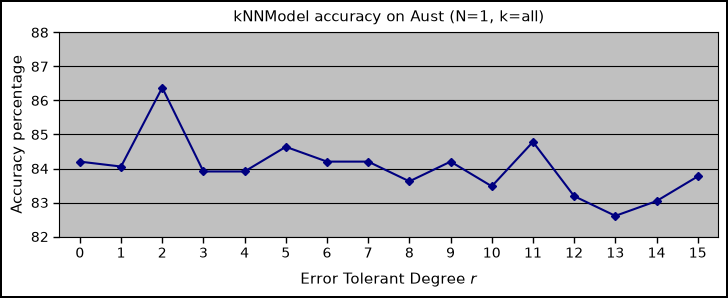

[GLASS] Best r=1 -> Accuracy=70.58%


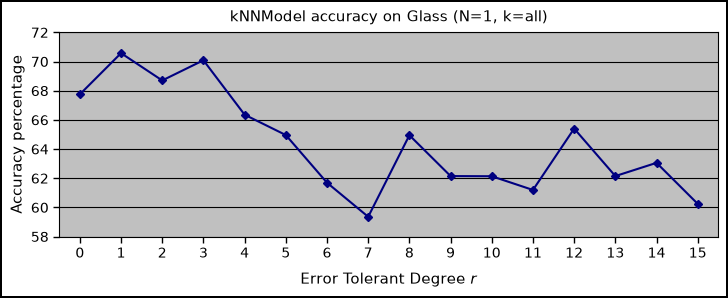

In [5]:
def run_and_plot_r_experiment(
    dataset_name: str,
    N: int = 1,
    k: int | str = "all",
    r_max: int = 15,
    ylim=None,
):
    r_list = list(range(0, r_max + 1))
    acc_list = []

    for r in r_list:
        res = evaluate_model(dataset_name, KNNModel(r=r, N=N, metric="euclidean"), k=k)
        acc_list.append(res["acc_mean"])

    best_idx = int(np.argmax(acc_list))
    print(f"[{dataset_name.upper()}] Best r={r_list[best_idx]} -> Accuracy={acc_list[best_idx]:.2f}%")

    plot_knn_r_curve(
        r_list,
        acc_list,
        title=f"kNNModel accuracy on {dataset_name.capitalize()} (N={N}, k={k})",
        ylim=ylim,
    )
    return pd.DataFrame({"r": r_list, "Accuracy (%)": np.round(acc_list, 2)})


df_aust_r = run_and_plot_r_experiment("aust", N=1, k=FEATURE_K["aust"], ylim=(82, 88))
df_glass_r = run_and_plot_r_experiment("glass", N=1, k=FEATURE_K["glass"], ylim=(58, 72))

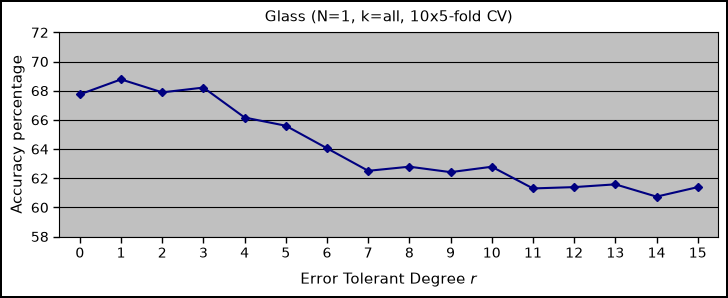

[GLASS] Best r=2 -> Accuracy=69.15%


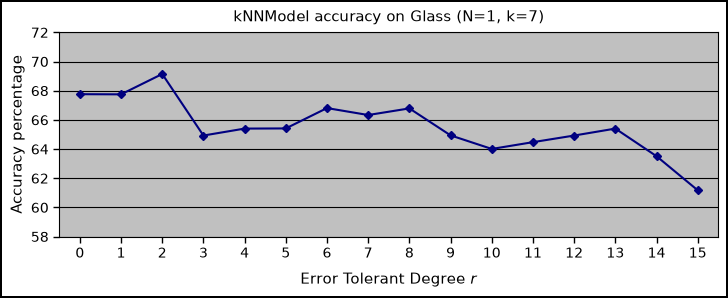

,r,Accuracy (%)
0,0,67.76
1,1,67.75
2,2,69.15
3,3,64.93
4,4,65.40
5,5,65.42
6,6,66.81
7,7,66.33
8,8,66.79
9,9,64.94


In [7]:
from sklearn.model_selection import RepeatedStratifiedKFold

# 1. Thử trung bình 10 lần 5-fold CV (triệt tiêu nhiễu do 1 seed cố định)
cv_repeat = RepeatedStratifiedKFold(n_splits=5, n_repeats=10, random_state=42)
r_list = list(range(16))
acc_repeat = [
    evaluate_model("glass", KNNModel(r=r, N=1), k="all", cv=cv_repeat)["acc_mean"]
    for r in r_list
]
plot_knn_r_curve(r_list, acc_repeat, title="Glass (N=1, k=all, 10x5-fold CV)", ylim=(58, 72))

# 2. Thử bật chọn đặc trưng Information Gain với k=7 trên 5-fold gốc
run_and_plot_r_experiment("glass", N=1, k=7, ylim=(58, 72))